# Wine Quality | MP5 — Grupo #4
## Avances 1–3: configuración, EDA, baseline e ingeniería de características (0–75 min)
Clasificación binaria; métrica principal F1 Macro. La auditoría independiente y el test siguen reservados.

In [1]:
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

inicio = perf_counter()
raiz = Path.cwd()
if not (raiz / 'datos_estudiantes').exists():
    raiz = raiz.parent
ruta = raiz / 'datos_estudiantes'
resultados = raiz / 'resultados'
resultados.mkdir(exist_ok=True)
tiempos = {}
t = perf_counter()
train = pd.read_csv(ruta / 'train_public.csv')
test = pd.read_csv(ruta / 'test_public_features.csv')
variables = [c for c in train.columns if c not in ['id', 'target']]
assert len(train) == 5197 and len(test) == 1300
assert test.columns.tolist() == ['id'] + variables
assert len(variables) == 11 and set(train.target.unique()) == {0, 1}
assert train.id.is_unique and test.id.is_unique
assert not set(train.id).intersection(test.id)
assert all(pd.api.types.is_numeric_dtype(train[c]) and pd.api.types.is_numeric_dtype(test[c]) for c in variables)
X = train[variables]
y = train['target']
tiempos['carga_y_validacion_s'] = perf_counter() - t
print('Train:', train.shape, '| Test:', test.shape)
print('Predictores:', len(variables))
print('IDs únicos y separados; test sin target.')
display(train.head())

Train: (5197, 13) | Test: (1300, 12)
Predictores: 11
IDs únicos y separados; test sin target.


,id,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,target
0,WINE_3610,6.8,0.33,0.30,2.1,0.047,35.0,147.0,0.98860,3.24,0.56,13.400000,0
1,WINE_4414,5.3,0.47,0.11,2.2,0.048,16.0,89.0,0.99182,3.54,0.88,13.566667,1
2,WINE_1156,6.6,0.36,0.28,6.1,0.029,12.0,93.0,0.99054,3.19,0.27,12.800000,0
3,WINE_3233,6.8,0.43,0.30,3.5,0.033,27.0,135.0,0.99060,3.00,0.37,12.000000,0
4,WINE_4269,6.5,0.24,0.38,1.0,0.027,31.0,90.0,0.98926,3.24,0.36,12.300000,0


## 1. Calidad de los datos
Se revisan faltantes, infinitos, perfiles fisicoquímicos repetidos y escalas. Los perfiles repetidos no se eliminan automáticamente: pueden ser mediciones legítimas. Se planifica una auditoría adicional por grupos de perfiles idénticos para medir generalización. La prueba pública se revisa únicamente en estructura y calidad, sin ajustar transformaciones con ella.

In [2]:
t = perf_counter()
calidad = pd.DataFrame({'nulos_train': X.isna().sum(), 'nulos_test': test[variables].isna().sum(),
                       'inf_train': np.isinf(X).sum(), 'inf_test': np.isinf(test[variables]).sum()})
display(calidad)
duplicados = int(X.duplicated().sum())
perfiles = train.groupby(variables, dropna=False)['target'].agg(['size', 'nunique'])
conflictos = int((perfiles['nunique'] > 1).sum())
print('Filas repetidas adicionales según predictores:', duplicados)
print('Perfiles con etiquetas diferentes:', conflictos)
print('IDs no son predictores.')
tiempos['control_calidad_s'] = perf_counter() - t

,nulos_train,nulos_test,inf_train,inf_test
fixed_acidity,0,0,0,0
volatile_acidity,0,0,0,0
citric_acid,0,0,0,0
residual_sugar,0,0,0,0
chlorides,0,0,0,0
free_sulfur_dioxide,0,0,0,0
total_sulfur_dioxide,0,0,0,0
density,0,0,0,0
pH,0,0,0,0
sulphates,0,0,0,0


Filas repetidas adicionales según predictores: 807
Perfiles con etiquetas diferentes: 1
IDs no son predictores.


## 2. Desbalance de clases
La exactitud de predecir siempre la clase mayoritaria no refleja la capacidad de identificar vinos superiores. Por ello se evaluará F1 Macro, que asigna el mismo peso al F1 de ambas clases.

,cantidad,proporcion
target,,
0,4369,0.840677
1,828,0.159323


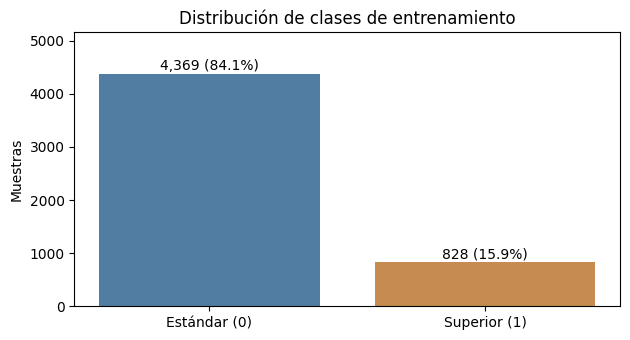

In [3]:
t = perf_counter()
clases = y.value_counts().sort_index()
resumen_clases = pd.DataFrame({'cantidad': clases, 'proporcion': clases/len(y)})
display(resumen_clases)
fig, ax = plt.subplots(figsize=(6.4,3.5))
ax.bar(['Estándar (0)', 'Superior (1)'], clases.values, color=['#527DA3','#C68B51'])
for i,n in enumerate(clases): ax.text(i,n+70,f'{n:,} ({n/len(y):.1%})',ha='center')
ax.set_ylim(0, max(clases)*1.18); ax.set_ylabel('Muestras'); ax.set_title('Distribución de clases de entrenamiento')
fig.tight_layout(); fig.savefig(resultados/'distribucion_clases.png',dpi=140); plt.show(); plt.close(fig)
tiempos['distribucion_clases_s'] = perf_counter()-t

## 3. Distribuciones, escalas y valores extremos
El rango de densidad y el de dióxido de azufre son muy distintos. Sin escalado, las variables con mayor magnitud pueden dominar una distancia euclidiana o Manhattan y afectar la optimización de una MLP. Se usa el criterio de 1,5 IQR para identificar valores extremos, no para descartarlos automáticamente.

,count,mean,std,min,25%,50%,75%,max,rango,extremos_IQR,porcentaje_extremos
fixed_acidity,5197.0,7.22021,1.29898,3.90000,6.40000,7.00000,7.700,15.60000,11.70000,292,5.61863
volatile_acidity,5197.0,0.33894,0.16337,0.08000,0.23000,0.29000,0.400,1.58000,1.50000,294,5.65711
citric_acid,5197.0,0.31929,0.14394,0.00000,0.25000,0.31000,0.390,1.66000,1.66000,397,7.63902
residual_sugar,5197.0,5.47392,4.78918,0.60000,1.80000,3.10000,8.100,65.80000,65.20000,97,1.86646
chlorides,5197.0,0.05592,0.03537,0.00900,0.03800,0.04700,0.065,0.61100,0.60200,224,4.31018
free_sulfur_dioxide,5197.0,30.46123,17.55997,1.00000,17.00000,29.00000,41.000,289.00000,288.00000,44,0.84664
total_sulfur_dioxide,5197.0,116.11863,56.47037,6.00000,79.00000,118.00000,156.000,440.00000,434.00000,6,0.11545
density,5197.0,0.99471,0.00302,0.98711,0.99235,0.99489,0.997,1.03898,0.05187,3,0.05773
pH,5197.0,3.21744,0.15989,2.72000,3.11000,3.21000,3.320,4.01000,1.29000,52,1.00058
sulphates,5197.0,0.53183,0.15115,0.22000,0.43000,0.51000,0.600,2.00000,1.78000,161,3.09794


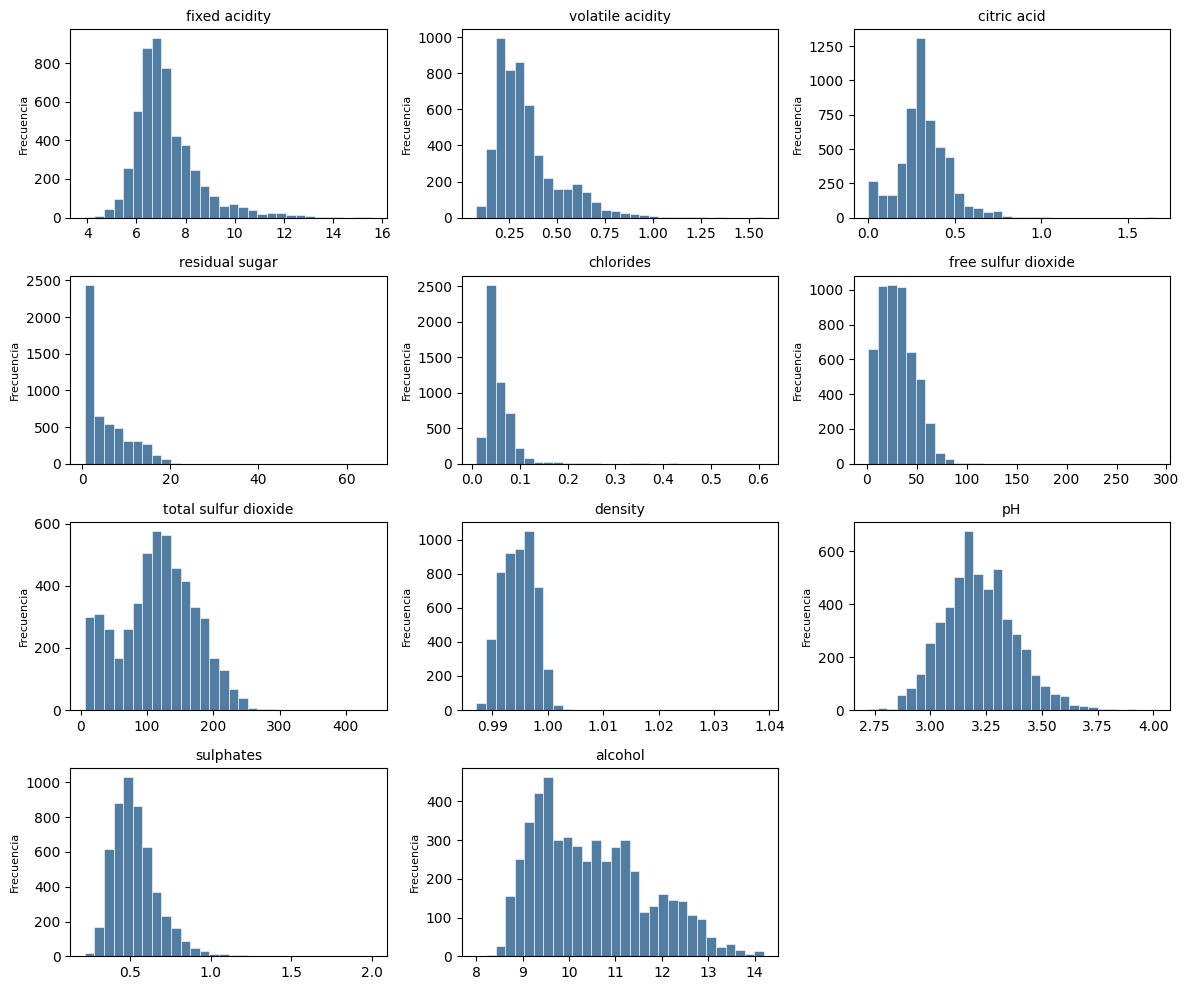

In [4]:
t = perf_counter()
q1 = X.quantile(.25); q3 = X.quantile(.75); iqr = q3-q1
extremos = ((X < q1-1.5*iqr) | (X > q3+1.5*iqr)).sum()
estadisticas = X.describe().T
estadisticas['rango'] = X.max()-X.min()
estadisticas['extremos_IQR'] = extremos
estadisticas['porcentaje_extremos'] = extremos/len(X)*100
display(estadisticas.round(5))
fig, axs = plt.subplots(4,3,figsize=(12,10))
for i,c in enumerate(variables):
    ax=axs.flat[i]; ax.hist(X[c],bins=30,color='#527DA3',edgecolor='white',linewidth=.4)
    ax.set_title(c.replace('_',' '),fontsize=10); ax.set_ylabel('Frecuencia',fontsize=8)
axs.flat[-1].axis('off'); fig.tight_layout(); fig.savefig(resultados/'distribuciones.png',dpi=130); plt.show(); plt.close(fig)
tiempos['distribuciones_y_extremos_s'] = perf_counter()-t

## 4. Correlaciones y relación con el objetivo
La matriz de Pearson describe relaciones lineales, no causalidad. Las variables con correlación baja no se eliminan sin validación: pueden aportar información no lineal o complementar otras variables.

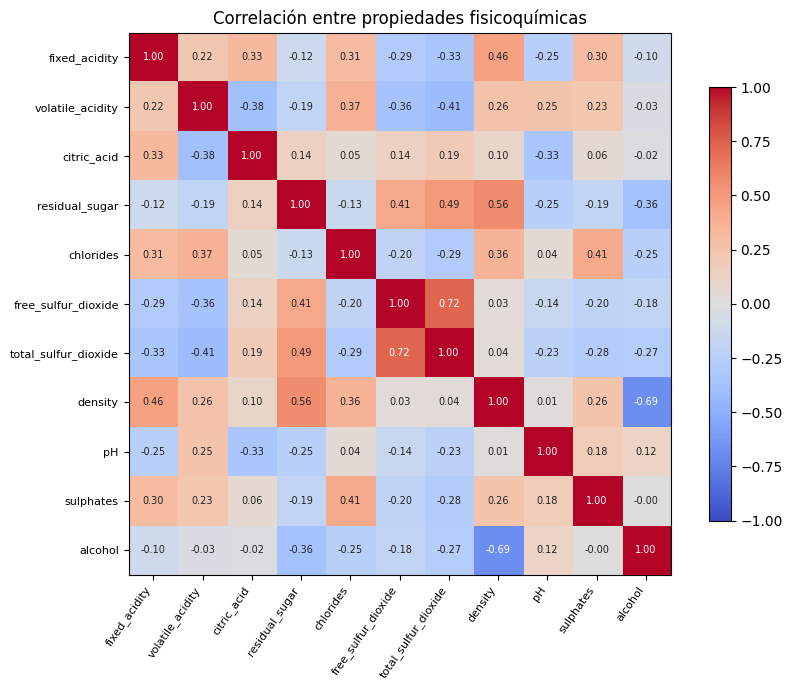

,correlacion_target
total_sulfur_dioxide,-0.475773
sulphates,0.360172
fixed_acidity,0.322606
free_sulfur_dioxide,-0.288943
volatile_acidity,0.268939
chlorides,0.240906
residual_sugar,-0.211429
pH,0.203617
alcohol,0.181199
density,0.152174


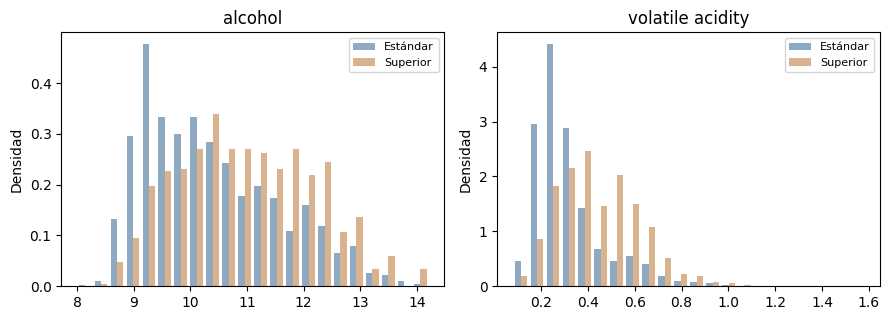

In [5]:
t=perf_counter()
corr = X.corr()
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(variables)),variables,rotation=55,ha='right',fontsize=8)
ax.set_yticks(range(len(variables)),variables,fontsize=8)
for i in range(len(variables)):
    for j in range(len(variables)):
        v=corr.iloc[i,j]; ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=7,color='white' if abs(v)>.65 else '#212121')
fig.colorbar(im,ax=ax,shrink=.8); ax.set_title('Correlación entre propiedades fisicoquímicas')
fig.tight_layout(); fig.savefig(resultados/'correlaciones.png',dpi=140); plt.show(); plt.close(fig)
relacion = train[variables+['target']].corr()['target'].drop('target').sort_values(key=abs,ascending=False)
display(relacion.to_frame('correlacion_target'))
fig,axs=plt.subplots(1,2,figsize=(9,3.3))
for ax,c in zip(axs,['alcohol','volatile_acidity']):
    ax.hist([train.loc[y==0,c],train.loc[y==1,c]],bins=22,density=True,alpha=.65,label=['Estándar','Superior'],color=['#527DA3','#C68B51'])
    ax.set_title(c.replace('_',' ')); ax.set_ylabel('Densidad'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(resultados/'variables_por_clase.png',dpi=140); plt.show(); plt.close(fig)
tiempos['correlaciones_s'] = perf_counter()-t

## 5. Decisiones para el siguiente avance
- Conservar las 11 variables; `id` solo identifica la muestra y `target` es la salida.
- Estandarizar con z-score, ajustando media y desviación únicamente dentro de cada fold de entrenamiento. Comparar otras escalas más adelante si aportan.
- No eliminar los extremos ni los duplicados sin evidencia de error; registrar el riesgo de generalización por perfiles repetidos.
- Si se requiere imputación, ajustar la mediana dentro del pipeline de entrenamiento.
- Reservar una partición estratificada de auditoría y comparar modelos mediante validación cruzada estratificada sobre el resto.
- Momento siguiente a la EDA: baseline k-NN con k=3, 5, 7 y distancias euclidiana y Manhattan. El cálculo de ratios, PCA, SVM y MLP se reserva para los momentos siguientes.


In [6]:
t=perf_counter()
estadisticas.to_csv(resultados/'estadisticas_train.csv')
calidad.to_csv(resultados/'calidad_datos.csv')
resumen_clases.to_csv(resultados/'clases.csv')
corr.to_csv(resultados/'correlaciones.csv')
relacion.to_csv(resultados/'correlacion_target.csv')
tiempos['guardar_tablas_s'] = perf_counter()-t
tiempos['total_eda_s'] = perf_counter()-inicio
resumen = {'filas_train':len(train), 'filas_test':len(test), 'predictores':len(variables),
           'clase_0':int(clases.loc[0]), 'clase_1':int(clases.loc[1]), 'duplicados_train':duplicados,
           'perfiles_etiquetas_distintas':conflictos, 'nulos_train':int(X.isna().sum().sum()),
           'nulos_test':int(test[variables].isna().sum().sum()), 'tiempos_s':tiempos}
(resultados/'resumen_eda.json').write_text(json.dumps(resumen,indent=2),encoding='utf-8')
display(pd.Series(tiempos,name='segundos').to_frame().round(4))

,segundos
carga_y_validacion_s,0.0123
control_calidad_s,0.0106
distribucion_clases_s,0.1335
distribuciones_y_extremos_s,1.1105
correlaciones_s,0.7421
guardar_tablas_s,0.0061
total_eda_s,2.0601


---
## 6. Momento 3 — Baseline k-NN (30–50 min)
Comparamos los seis casos solicitados: k = 3, 5, 7 y distancias euclidiana y Manhattan. Se utilizan las 11 características originales y voto uniforme. Se separa un 20% del entrenamiento público como auditoría independiente para la etapa final; sobre el 80% restante se realiza validación cruzada estratificada de 3 folds, con semilla 42. El escalador y la imputación por mediana se ajustan exclusivamente con cada fold de entrenamiento. La prueba pública y la auditoría independiente no participan en la elección del baseline.

- Euclidiana: raíz de la suma de diferencias cuadráticas.
- Manhattan: suma de diferencias absolutas.
- F1 Macro: promedio del F1 de las clases 0 y 1. Se reportan también accuracy, precision, recall y F1 de la clase superior.
- OOF: cada registro del conjunto de desarrollo se predice una vez por un modelo que no lo vio en ese fold. Se reporta tanto F1 Macro OOF como la media y dispersión por fold.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix
from threadpoolctl import threadpool_limits

SEMILLA = 42
inicio_baseline = perf_counter()
dev, hold = train_test_split(np.arange(len(X)), test_size=.2, random_state=SEMILLA, stratify=y)
Xd = X.iloc[dev]
yd = y.iloc[dev].to_numpy()
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA).split(Xd, yd))
print('Desarrollo:', len(dev), '| Auditoría reservada:', len(hold))
print('Folds:', [(len(tr), len(va)) for tr, va in folds])

def crear_knn(k, distancia):
    return Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler()),
        ('modelo', KNeighborsClassifier(n_neighbors=k, metric=distancia, weights='uniform', n_jobs=1))
    ])

def calcular_metricas(real, pred):
    return {'f1_macro': f1_score(real, pred, average='macro'),
            'accuracy': accuracy_score(real, pred),
            'precision_1': precision_score(real, pred, zero_division=0),
            'recall_1': recall_score(real, pred, zero_division=0),
            'f1_1': f1_score(real, pred, zero_division=0)}

Desarrollo: 4157 | Auditoría reservada: 1040
Folds: [(2771, 1386), (2771, 1386), (2772, 1385)]


### 6.1 Comparación de las seis configuraciones
Se mide por separado el ajuste del pipeline y la inferencia del fold de validación (incluyendo su transformación). Se ejecuta un candidato a la vez con un hilo para limitar recursos. El umbral es 0,5; no se optimizan todavía pesos ni umbrales.

In [8]:
filas = []
detalle = []
predicciones_oof = {}
inicio_busqueda = perf_counter()
with threadpool_limits(limits=1):
    for k in [3, 5, 7]:
        for distancia in ['euclidean', 'manhattan']:
            inicio_candidato = perf_counter()
            pred_oof = np.empty(len(yd), dtype=int)
            tiempos_fit = []
            tiempos_pred = []
            f1_folds = []
            for i, (tr, va) in enumerate(folds, start=1):
                modelo = crear_knn(k, distancia)
                t = perf_counter()
                modelo.fit(Xd.iloc[tr], yd[tr])
                ajuste = perf_counter() - t
                t = perf_counter()
                pred = modelo.predict(Xd.iloc[va])
                inferencia = perf_counter() - t
                pred_oof[va] = pred
                met = calcular_metricas(yd[va], pred)
                detalle.append({'k':k, 'distancia':distancia, 'fold':i,
                                'n_train':len(tr), 'n_validacion':len(va),
                                'ajuste_s':ajuste, 'inferencia_s':inferencia, **met})
                tiempos_fit.append(ajuste)
                tiempos_pred.append(inferencia)
                f1_folds.append(met['f1_macro'])
            predicciones_oof[(k, distancia)] = pred_oof
            filas.append({'k':k, 'distancia':distancia, **calcular_metricas(yd, pred_oof),
                          'f1_media_folds':np.mean(f1_folds), 'f1_std_folds':np.std(f1_folds),
                          'ajuste_medio_s':np.mean(tiempos_fit), 'inferencia_media_s':np.mean(tiempos_pred),
                          'ajuste_total_s':sum(tiempos_fit), 'inferencia_total_s':sum(tiempos_pred),
                          'tiempo_total_s':perf_counter()-inicio_candidato})
tiempo_busqueda = perf_counter() - inicio_busqueda
comparacion = pd.DataFrame(filas).sort_values('f1_macro', ascending=False).reset_index(drop=True)
detalle_folds = pd.DataFrame(detalle)
display(comparacion.round(5))
mejor = comparacion.iloc[0]
k_mejor, distancia_mejor = int(mejor.k), mejor.distancia
pred_mejor = predicciones_oof[(k_mejor, distancia_mejor)]
print(f'Baseline seleccionado: k={k_mejor}, {distancia_mejor}, F1 Macro OOF={mejor.f1_macro:.4f}')

,k,distancia,f1_macro,accuracy,precision_1,recall_1,f1_1,f1_media_folds,f1_std_folds,ajuste_medio_s,inferencia_media_s,ajuste_total_s,inferencia_total_s,tiempo_total_s
0,3,manhattan,0.78887,0.88790,0.65123,0.63746,0.64427,0.78883,0.01014,0.00625,0.04266,0.01875,0.12797,0.17221
1,7,manhattan,0.78832,0.89391,0.69767,0.58912,0.63882,0.78830,0.00164,0.00569,0.04679,0.01707,0.14038,0.17628
2,3,euclidean,0.78653,0.88694,0.64907,0.63142,0.64012,0.78646,0.00405,0.00674,0.02553,0.02021,0.07659,0.11485
3,7,euclidean,0.78440,0.89151,0.68673,0.58610,0.63244,0.78430,0.00593,0.00615,0.03246,0.01844,0.09738,0.13241
4,5,manhattan,0.78221,0.88886,0.67065,0.59366,0.62981,0.78215,0.01134,0.00714,0.04980,0.02142,0.14940,0.19021
5,5,euclidean,0.78183,0.89006,0.68078,0.58308,0.62815,0.78186,0.00543,0.00618,0.02975,0.01855,0.08924,0.12593


Baseline seleccionado: k=3, manhattan, F1 Macro OOF=0.7889


### 6.2 Resultados y matriz de confusión
La clase superior es la minoritaria. Se usa la matriz OOF para identificar falsos positivos y falsos negativos, sin evaluar aún la partición independiente. Predecir siempre la clase estándar solo sirve como referencia de desbalance.

Referencia clase mayoritaria: {'f1_macro': 0.4567433350757972, 'accuracy': 0.8407505412557132, 'precision_1': 0.0, 'recall_1': 0.0, 'f1_1': 0.0}


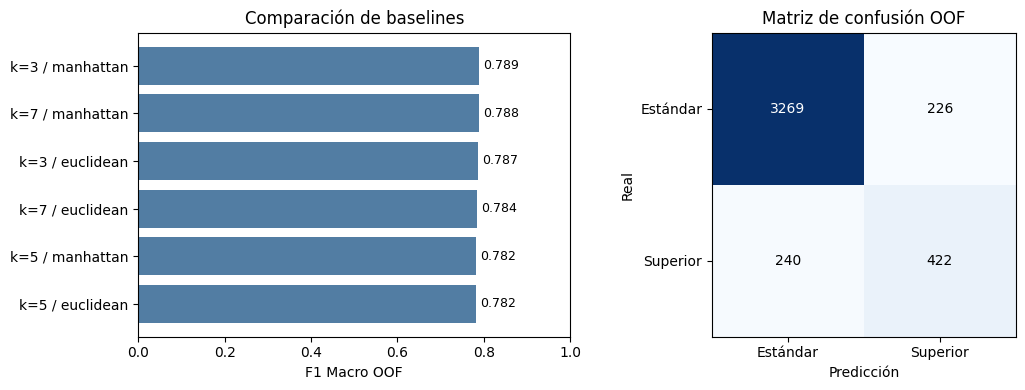

Matriz: [[3269, 226], [240, 422]]


In [9]:
referencia = calcular_metricas(yd, np.zeros(len(yd),dtype=int))
print('Referencia clase mayoritaria:', referencia)
matriz = confusion_matrix(yd, pred_mejor, labels=[0,1])
fig, axs = plt.subplots(1,2,figsize=(11,4))
etiquetas = ['k='+str(k)+' / '+d for k,d in zip(comparacion.k, comparacion.distancia)]
axs[0].barh(etiquetas[::-1], comparacion.f1_macro.iloc[::-1], color='#527DA3')
axs[0].set_xlim(0,1); axs[0].set_xlabel('F1 Macro OOF'); axs[0].set_title('Comparación de baselines')
for i,v in enumerate(comparacion.f1_macro.iloc[::-1]): axs[0].text(v+.01,i,f'{v:.3f}',va='center',fontsize=9)
axs[1].imshow(matriz,cmap='Blues'); axs[1].set_xticks([0,1],['Estándar','Superior']); axs[1].set_yticks([0,1],['Estándar','Superior'])
axs[1].set_xlabel('Predicción'); axs[1].set_ylabel('Real'); axs[1].set_title('Matriz de confusión OOF')
for i in range(2):
    for j in range(2): axs[1].text(j,i,str(matriz[i,j]),ha='center',va='center',color='white' if matriz[i,j]>matriz.max()/2 else 'black')
fig.tight_layout(); fig.savefig(resultados/'baseline_comparacion.png',dpi=140); plt.show(); plt.close(fig)
print('Matriz:', matriz.tolist())

### 6.3 Auditoría adicional de perfiles repetidos
Los registros con las mismas 11 propiedades pueden aparecer en folds distintos de una partición aleatoria. Para comprobar la sensibilidad del baseline elegido, se repite su evaluación con StratifiedGroupKFold, manteniendo perfiles idénticos juntos. Es una auditoría complementaria, no la métrica oficial de selección ni el conjunto independiente reservado.

In [10]:
inicio_grupos = perf_counter()
grupos = pd.util.hash_pandas_object(Xd, index=False).to_numpy()
pred_grupos = np.empty(len(yd), dtype=int)
with threadpool_limits(limits=1):
    for tr, va in StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA).split(Xd, yd, grupos):
        assert not set(grupos[tr]).intersection(grupos[va])
        modelo = crear_knn(k_mejor, distancia_mejor)
        modelo.fit(Xd.iloc[tr], yd[tr])
        pred_grupos[va] = modelo.predict(Xd.iloc[va])
audit_grupos = calcular_metricas(yd, pred_grupos)
tiempo_grupos = perf_counter()-inicio_grupos
print('Auditoría por grupos:', audit_grupos)

Auditoría por grupos: {'f1_macro': 0.7818803709637949, 'accuracy': 0.886937695453452, 'precision_1': 0.6573770491803279, 'recall_1': 0.6057401812688822, 'f1_1': 0.6305031446540881}


### 6.4 Registro del avance
Se conserva el baseline como punto de comparación. El siguiente momento incorpora variables fisicoquímicas adicionales y PCA; los modelos SVM, MLP y la selección final todavía no forman parte de este avance.

In [11]:
comparacion.to_csv(resultados/'baseline_metricas.csv',index=False)
detalle_folds.to_csv(resultados/'baseline_folds.csv',index=False)
resumen_baseline = {'semilla': SEMILLA, 'n_desarrollo':len(dev), 'n_auditoria_reservada':len(hold),
    'n_folds':len(folds), 'configuraciones':len(comparacion), 'ajustes_cv':len(detalle_folds),
    'mejor':mejor.to_dict(), 'matriz_confusion_oof':matriz.tolist(),
    'referencia_mayoritaria':referencia, 'auditoria_grupos':audit_grupos,
    'tiempo_busqueda_s':tiempo_busqueda, 'tiempo_auditoria_grupos_s':tiempo_grupos,
    'tiempo_momento3_s':perf_counter()-inicio_baseline}
(resultados/'resumen_baseline.json').write_text(json.dumps(resumen_baseline,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(resumen_baseline,indent=2,ensure_ascii=False))

{
  "semilla": 42,
  "n_desarrollo": 4157,
  "n_auditoria_reservada": 1040,
  "n_folds": 3,
  "configuraciones": 6,
  "ajustes_cv": 18,
  "mejor": {
    "k": 3,
    "distancia": "manhattan",
    "f1_macro": 0.7888706998400041,
    "accuracy": 0.8878999278325715,
    "precision_1": 0.6512345679012346,
    "recall_1": 0.6374622356495468,
    "f1_1": 0.6442748091603053,
    "f1_media_folds": 0.788828173315031,
    "f1_std_folds": 0.010136029921865405,
    "ajuste_medio_s": 0.006251120333217841,
    "inferencia_media_s": 0.042656011666319195,
    "ajuste_total_s": 0.018753360999653523,
    "inferencia_total_s": 0.1279680349989576,
    "tiempo_total_s": 0.1722113489995536
  },
  "matriz_confusion_oof": [
    [
      3269,
      226
    ],
    [
      240,
      422
    ]
  ],
  "referencia_mayoritaria": {
    "f1_macro": 0.4567433350757972,
    "accuracy": 0.8407505412557132,
    "precision_1": 0.0,
    "recall_1": 0.0,
    "f1_1": 0.0
  },
  "auditoria_grupos": {
    "f1_macro": 0.78188037

---
## 7. Momento 4: Feature engineering y PCA (50–75 min)
Se agregan tres características propuestas por la guía: acidez fija / volátil (balance de acidez), SO₂ libre / total (fracción libre), alcohol / densidad (relación entre composición y densidad). No implican causalidad. Se preservan las 11 variables originales; los denominadores cero se convierten en faltantes y se imputan dentro del fold.

PCA proyecta los datos estandarizados en direcciones de máxima varianza: $\Sigma=Z^TZ/(n-1)$, $\Sigma v_i=\lambda_i v_i$, $T=ZV_d$. Se comparan 91% y 95% de varianza con la representación sin PCA. El escalado, imputación y PCA se ajustan exclusivamente dentro de cada fold.

In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import FunctionTransformer
inicio_fe=perf_counter()
def agregar_ratios(datos):
    datos=datos.copy()
    datos['ratio_acidez']=datos.fixed_acidity/datos.volatile_acidity.replace(0,np.nan)
    datos['ratio_so2']=datos.free_sulfur_dioxide/datos.total_sulfur_dioxide.replace(0,np.nan)
    datos['ratio_alcohol_densidad']=datos.alcohol/datos.density.replace(0,np.nan)
    return datos.replace([np.inf,-np.inf],np.nan)
ratios_dev=agregar_ratios(Xd)
nuevas=['ratio_acidez','ratio_so2','ratio_alcohol_densidad']
resumen_ratios=ratios_dev[nuevas].describe().T
resumen_ratios['nulos']=ratios_dev[nuevas].isna().sum()
resumen_ratios['correlacion_target']=[ratios_dev[c].corr(pd.Series(yd,index=Xd.index)) for c in nuevas]
display(resumen_ratios.round(4))
resumen_ratios.to_csv(resultados/'ratios_estadisticas.csv')
def crear_knn_pca(ratios,pca,k,distancia,pesos):
    return Pipeline([('ratios',FunctionTransformer(agregar_ratios,validate=False) if ratios else 'passthrough'),('imputar',SimpleImputer(strategy='median')),('escalar',StandardScaler()),('pca',PCA(n_components=pca,svd_solver='full') if pca else 'passthrough'),('modelo',KNeighborsClassifier(n_neighbors=k,metric=distancia,weights=pesos,n_jobs=1))])

,count,mean,std,min,25%,50%,75%,max,nulos,correlacion_target
ratio_acidez,4157.0,25.3644,10.7132,4.8101,17.7143,23.9286,31.0000,90.0000,0,-0.1335
ratio_so2,4157.0,0.2868,0.1248,0.0227,0.2031,0.2698,0.3478,0.8421,0,0.3757
ratio_alcohol_densidad,4157.0,10.5325,1.2241,8.0250,9.5248,10.3220,11.3923,14.1790,0,0.1780


### 7.1 Comparación controlada y exploración
Se conserva el baseline (k=3, Manhattan, voto uniforme) para aislar el efecto de ratios y PCA; también se comparan k=3, 7, 15 y 50 con peso inverso a la distancia y ambas métricas. Se mantienen las mismas particiones y la regla de decisión nativa sin optimizar umbrales todavía. Se registran tiempos por fold y F1 Macro OOF.

In [13]:
configs=[]
for ratios in [False,True]:
    for pca in [0,.91,.95]:
        configs.append((ratios,pca,k_mejor,distancia_mejor,'uniform'))
        for k in [3,7,15,50]:
            for distancia in ['euclidean','manhattan']:
                configs.append((ratios,pca,k,distancia,'distance'))
filas_fe,detalle_fe,pred_fe=[],[],{}
inicio_busqueda_fe=perf_counter()
with threadpool_limits(limits=1):
    for i,(ratios,pca,k,distancia,pesos) in enumerate(configs):
        inicio_candidato=perf_counter()
        pred_oof=np.empty(len(yd),dtype=int)
        registros=[]
        for fold,(tr,va) in enumerate(folds,start=1):
            modelo=crear_knn_pca(ratios,pca,k,distancia,pesos)
            t=perf_counter(); modelo.fit(Xd.iloc[tr],yd[tr]); ajuste=perf_counter()-t
            t=perf_counter(); pred=modelo.predict(Xd.iloc[va]); inferencia=perf_counter()-t
            pred_oof[va]=pred
            componentes=int(modelo.named_steps['pca'].n_components_) if pca else (14 if ratios else 11)
            retenida=float(modelo.named_steps['pca'].explained_variance_ratio_.sum()) if pca else 1.
            fila=dict(config=i,ratios=ratios,pca=pca,k=k,distancia=distancia,pesos=pesos,fold=fold,componentes=componentes,varianza_retenida=retenida,ajuste_s=ajuste,inferencia_s=inferencia,**calcular_metricas(yd[va],pred))
            registros.append(fila); detalle_fe.append(fila)
        d=pd.DataFrame(registros); pred_fe[i]=pred_oof
        filas_fe.append(dict(config=i,ratios=ratios,pca=pca,k=k,distancia=distancia,pesos=pesos,**calcular_metricas(yd,pred_oof),f1_media_folds=d.f1_macro.mean(),f1_std_folds=d.f1_macro.std(ddof=0),componentes_media=d.componentes.mean(),varianza_media=d.varianza_retenida.mean(),ajuste_medio_s=d.ajuste_s.mean(),inferencia_media_s=d.inferencia_s.mean(),tiempo_total_s=perf_counter()-inicio_candidato))
tiempo_busqueda_fe=perf_counter()-inicio_busqueda_fe
comparacion_fe=pd.DataFrame(filas_fe).sort_values('f1_macro',ascending=False).reset_index(drop=True)
detalle_fe=pd.DataFrame(detalle_fe)
mejor_fe=comparacion_fe.iloc[0]
control=comparacion_fe[comparacion_fe.pesos=='uniform'].sort_values(['ratios','pca'])
display(control.round(5)); display(comparacion_fe.head(10).round(5))
print('Configuraciones:',len(comparacion_fe),'Ajustes:',len(detalle_fe))

,config,ratios,pca,k,distancia,pesos,f1_macro,accuracy,precision_1,recall_1,f1_1,f1_media_folds,f1_std_folds,componentes_media,varianza_media,ajuste_medio_s,inferencia_media_s,tiempo_total_s
51,0,False,0.00,3,manhattan,uniform,0.78887,0.88790,0.65123,0.63746,0.64427,0.78883,0.01014,11.0,1.00000,0.00719,0.04503,0.17616
53,9,False,0.91,3,manhattan,uniform,0.77279,0.88116,0.63462,0.59819,0.61586,0.77271,0.01048,8.0,0.94544,0.00642,0.02387,0.10799
52,18,False,0.95,3,manhattan,uniform,0.78226,0.88598,0.65016,0.61480,0.63199,0.78215,0.00791,9.0,0.97585,0.00599,0.02814,0.11948
49,27,True,0.00,3,manhattan,uniform,0.79335,0.89199,0.67095,0.63142,0.65058,0.79326,0.00242,14.0,1.00000,0.00830,0.05365,0.20331
50,36,True,0.91,3,manhattan,uniform,0.79165,0.88958,0.65736,0.64048,0.64881,0.79179,0.00803,8.0,0.92250,0.00821,0.02674,0.12116
48,45,True,0.95,3,manhattan,uniform,0.79496,0.89127,0.66254,0.64653,0.65443,0.79472,0.00611,9.0,0.95841,0.00805,0.03090,0.13370


,config,ratios,pca,k,distancia,pesos,f1_macro,accuracy,precision_1,recall_1,f1_1,f1_media_folds,f1_std_folds,componentes_media,varianza_media,ajuste_medio_s,inferencia_media_s,tiempo_total_s
0,26,False,0.95,50,manhattan,distance,0.82617,0.91484,0.79278,0.62991,0.70202,0.82625,0.00655,9.0,0.97585,0.00648,0.05359,0.19766
1,8,False,0.00,50,manhattan,distance,0.82592,0.91436,0.78759,0.63293,0.70184,0.82615,0.01004,11.0,1.00000,0.00600,0.06480,0.23155
2,43,True,0.91,50,euclidean,distance,0.82591,0.91388,0.78148,0.63746,0.70216,0.82609,0.00895,8.0,0.92250,0.00920,0.03616,0.15429
3,4,False,0.00,7,manhattan,distance,0.82553,0.91003,0.73920,0.67221,0.70411,0.82569,0.00658,11.0,1.00000,0.00797,0.05174,0.19617
4,7,False,0.00,50,euclidean,distance,0.82506,0.91364,0.78212,0.63444,0.70058,0.82521,0.00698,11.0,1.00000,0.00621,0.05556,0.20367
5,49,True,0.95,7,manhattan,distance,0.82287,0.90931,0.74112,0.66163,0.69912,0.82302,0.00646,9.0,0.95841,0.00799,0.03622,0.15052
6,40,True,0.91,7,manhattan,distance,0.82098,0.90883,0.74271,0.65408,0.69558,0.82117,0.00835,8.0,0.92250,0.00824,0.03328,0.14222
7,35,True,0.00,50,manhattan,distance,0.82070,0.91340,0.79842,0.61027,0.69178,0.82085,0.00756,14.0,1.00000,0.00869,0.07769,0.27748
8,44,True,0.91,50,manhattan,distance,0.82064,0.91220,0.78286,0.62085,0.69250,0.82050,0.00666,8.0,0.92250,0.00846,0.05150,0.19777
9,48,True,0.95,7,euclidean,distance,0.82063,0.90811,0.73649,0.65861,0.69537,0.82109,0.01439,9.0,0.95841,0.00820,0.02161,0.10697


Configuraciones: 54 Ajustes: 162


### 7.2 Análisis PCA y resultados
La curva de varianza se ajusta al conjunto de desarrollo para visualización; la validación predictiva utiliza PCA ajustado por fold. Retener varianza no garantiza conservar la señal que distingue las clases. Se muestra el mejor resultado por representación y se conserva el baseline como referencia.

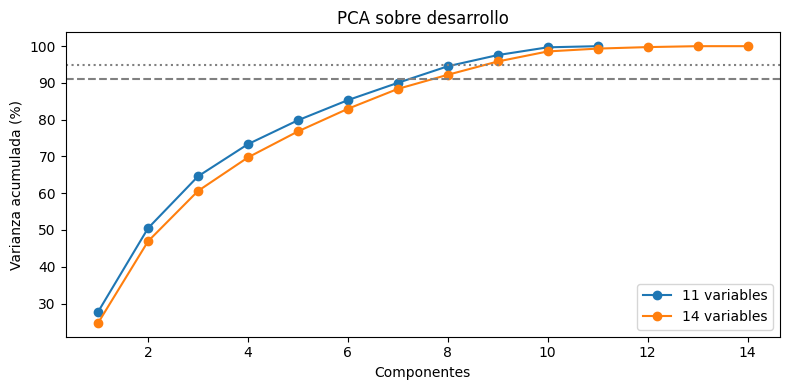

,config,ratios,pca,k,distancia,pesos,f1_macro,accuracy,precision_1,recall_1,f1_1,f1_media_folds,f1_std_folds,componentes_media,varianza_media,ajuste_medio_s,inferencia_media_s,tiempo_total_s
0,26,False,0.95,50,manhattan,distance,0.82617,0.91484,0.79278,0.62991,0.70202,0.82625,0.00655,9.0,0.97585,0.00648,0.05359,0.19766
1,8,False,0.00,50,manhattan,distance,0.82592,0.91436,0.78759,0.63293,0.70184,0.82615,0.01004,11.0,1.00000,0.00600,0.06480,0.23155
2,43,True,0.91,50,euclidean,distance,0.82591,0.91388,0.78148,0.63746,0.70216,0.82609,0.00895,8.0,0.92250,0.00920,0.03616,0.15429
5,49,True,0.95,7,manhattan,distance,0.82287,0.90931,0.74112,0.66163,0.69912,0.82302,0.00646,9.0,0.95841,0.00799,0.03622,0.15052
7,35,True,0.00,50,manhattan,distance,0.82070,0.91340,0.79842,0.61027,0.69178,0.82085,0.00756,14.0,1.00000,0.00869,0.07769,0.27748
25,16,False,0.91,50,euclidean,distance,0.81620,0.91027,0.77735,0.61178,0.68470,0.81637,0.00698,8.0,0.94544,0.00685,0.03575,0.14728


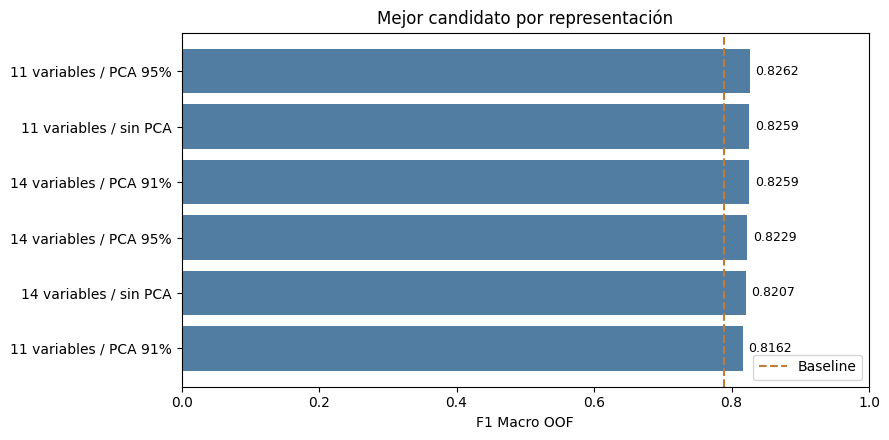

Matriz OOF: [[3386, 109], [245, 417]]


In [14]:
fig,ax=plt.subplots(figsize=(8,4))
for ratios in [False,True]:
    Z=crear_knn_pca(ratios,0,3,'manhattan','uniform')[:-2].fit_transform(Xd)
    espectro=PCA(svd_solver='full').fit(Z).explained_variance_ratio_.cumsum()
    ax.plot(np.arange(1,len(espectro)+1),espectro*100,marker='o',label='14 variables' if ratios else '11 variables')
ax.axhline(91,ls='--',color='gray'); ax.axhline(95,ls=':',color='gray'); ax.set(xlabel='Componentes',ylabel='Varianza acumulada (%)',title='PCA sobre desarrollo'); ax.legend(); fig.tight_layout(); fig.savefig(resultados/'pca_varianza.png',dpi=140); plt.show(); plt.close(fig)
mejores_repr=comparacion_fe.groupby(['ratios','pca'],sort=False).head(1)
display(mejores_repr.round(5))
fig,ax=plt.subplots(figsize=(9,4.5))
labels=[f"{'14' if r else '11'} variables / {'sin PCA' if p==0 else 'PCA '+str(int(p*100))+'%'}" for r,p in zip(mejores_repr.ratios,mejores_repr.pca)]
ax.barh(labels[::-1],mejores_repr.f1_macro.iloc[::-1],color='#527DA3');ax.axvline(mejor.f1_macro,ls='--',color='#c17b38',label='Baseline');ax.set_xlim(0,1);ax.set_xlabel('F1 Macro OOF');ax.set_title('Mejor candidato por representación');ax.legend(loc='lower right')
for i,v in enumerate(mejores_repr.f1_macro.iloc[::-1]): ax.text(v+.008,i,f'{v:.4f}',va='center',fontsize=9)
fig.tight_layout();fig.savefig(resultados/'pca_comparacion.png',dpi=140);plt.show();plt.close(fig)
matriz_fe=confusion_matrix(yd,pred_fe[int(mejor_fe.config)],labels=[0,1]);print('Matriz OOF:',matriz_fe.tolist())

### 7.3 Auditoría y registro
Se repite el mejor candidato por F1 Macro con grupos de perfiles idénticos; no se selecciona por la auditoría. El holdout de 1040 registros sigue sin evaluar; la optimización de umbrales y SVM/MLP se reservan al momento 5.

In [15]:
inicio_audit_fe=perf_counter(); pred_grupos_fe=np.empty(len(yd),dtype=int)
with threadpool_limits(limits=1):
    for tr,va in StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEMILLA).split(Xd,yd,grupos):
        assert not set(grupos[tr]).intersection(grupos[va])
        modelo=crear_knn_pca(bool(mejor_fe.ratios),float(mejor_fe.pca),int(mejor_fe.k),mejor_fe.distancia,mejor_fe.pesos)
        modelo.fit(Xd.iloc[tr],yd[tr]);pred_grupos_fe[va]=modelo.predict(Xd.iloc[va])
audit_fe=calcular_metricas(yd,pred_grupos_fe);tiempo_audit_fe=perf_counter()-inicio_audit_fe
comparacion_fe.to_csv(resultados/'feature_pca_metricas.csv',index=False);detalle_fe.to_csv(resultados/'feature_pca_folds.csv',index=False);control.to_csv(resultados/'feature_pca_control.csv',index=False)
resumen_fe={'configuraciones':len(comparacion_fe),'ajustes_cv':len(detalle_fe),'mejor':mejor_fe.to_dict(),'baseline_f1':float(mejor.f1_macro),'mejora_pp':float(100*(mejor_fe.f1_macro-mejor.f1_macro)),'matriz_confusion_oof':matriz_fe.tolist(),'auditoria_grupos':audit_fe,'tiempo_busqueda_s':tiempo_busqueda_fe,'tiempo_auditoria_s':tiempo_audit_fe,'tiempo_momento4_s':perf_counter()-inicio_fe,'n_auditoria_reservada':len(hold)}
(resultados/'resumen_feature_pca.json').write_text(json.dumps(resumen_fe,indent=2,ensure_ascii=False),encoding='utf-8');print(json.dumps(resumen_fe,indent=2,ensure_ascii=False))

{
  "configuraciones": 54,
  "ajustes_cv": 162,
  "mejor": {
    "config": 26,
    "ratios": false,
    "pca": 0.95,
    "k": 50,
    "distancia": "manhattan",
    "pesos": "distance",
    "f1_macro": 0.8261714818689279,
    "accuracy": 0.9148424344479191,
    "precision_1": 0.7927756653992395,
    "recall_1": 0.6299093655589124,
    "f1_1": 0.702020202020202,
    "f1_media_folds": 0.8262469401991129,
    "f1_std_folds": 0.0065475490990561745,
    "componentes_media": 9.0,
    "varianza_media": 0.97584781014461,
    "ajuste_medio_s": 0.006479572666952056,
    "inferencia_media_s": 0.05359330166690294,
    "tiempo_total_s": 0.19765655099945434
  },
  "baseline_f1": 0.7888706998400041,
  "mejora_pp": 3.730078202892373,
  "matriz_confusion_oof": [
    [
      3386,
      109
    ],
    [
      245,
      417
    ]
  ],
  "auditoria_grupos": {
    "f1_macro": 0.7960345866071885,
    "accuracy": 0.9023334135193649,
    "precision_1": 0.7591093117408907,
    "recall_1": 0.5664652567975831,
 

### Conclusión del momento 4
El F1 Macro OOF aumenta de 0.7889 a 0.8262 con k=50, Manhattan, ponderación inversa y PCA de 9 componentes (97.58% de varianza media). La configuración sin PCA prácticamente empata (0.8259); no se puede afirmar superioridad estadística. Los ratios mejoran el baseline controlado, pero no son necesarios en el candidato principal. Su recall de clase 1 es 0.6299, menor al baseline (0.6375); se buscará un equilibrio con la optimización del umbral en el siguiente momento. El holdout continúa reservado.